# 03 · Imputation benchmark: Tangram vs SpaGE

Compares the leave-one-gene-out predictions from notebook 02 with the measured (log-normalised) expression on both MERFISH sections.

1. Per-gene metrics: Pearson, Spearman, RMSE, cosine, Jensen-Shannon (JS), SSIM
2. Which genes are imputed better than chance (cell-permutation test, BH-FDR)
3. Tangram vs SpaGE (paired Wilcoxon) and D1 vs D2 (Mann-Whitney)
4. What makes a gene easy to impute: spatial sparsity and spatial autocorrelation (Moran's I)

Needs only the core dependencies (no Tangram/TISSUE). Writes `results/gene_metrics.csv` (used by notebook 04) and `results/significant_genes/`.

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as st

from spatial_imputation import config, data, metrics, stats, plotting
plotting.set_style()

## Load processed data and predictions

In [2]:
DATASETS = ["d1", "d2"]
adatas, refs, actual = {}, {}, {}
for ds in DATASETS:
    adatas[ds], refs[ds] = data.load_analysis_inputs(ds)
    actual[ds] = data.expression_frame(adatas[ds])
    print(ds, adatas[ds].shape)

d1 (19441, 464)


d2 (51377, 296)


## 1 · Per-gene metrics

In [3]:
per_condition = {}
for ds in DATASETS:
    sparsity = data.sparsity_table(adatas[ds], refs[ds])
    for m in config.METHODS:
        gm = metrics.gene_metrics(adatas[ds].obsm[f"{m}_predictions"], actual[ds])
        per_condition[(m, ds)] = gm.join(sparsity)

tidy = metrics.tidy_metrics(per_condition)
cols = ["pearson_r", "spearman_r", "RMSE", "cosine_sim", "js", "ssim"]
tidy.groupby("label")[cols].agg(lambda s: f"{s.mean():.3f} ± {s.std():.3f}").loc[plotting.CONDITION_ORDER]

,pearson_r,spearman_r,RMSE,cosine_sim,js,ssim
label,,,,,,
Tangram (D1),0.314 ± 0.196,0.246 ± 0.156,1.223 ± 2.299,0.467 ± 0.222,0.405 ± 0.157,0.527 ± 0.209
SpaGE (D1),0.315 ± 0.200,0.241 ± 0.154,0.400 ± 0.297,0.437 ± 0.233,0.396 ± 0.163,0.648 ± 0.176
Tangram (D2),0.294 ± 0.178,0.237 ± 0.206,0.758 ± 0.493,0.813 ± 0.157,0.126 ± 0.112,0.501 ± 0.133
SpaGE (D2),0.262 ± 0.178,0.228 ± 0.194,0.798 ± 0.264,0.713 ± 0.192,0.168 ± 0.137,0.414 ± 0.109


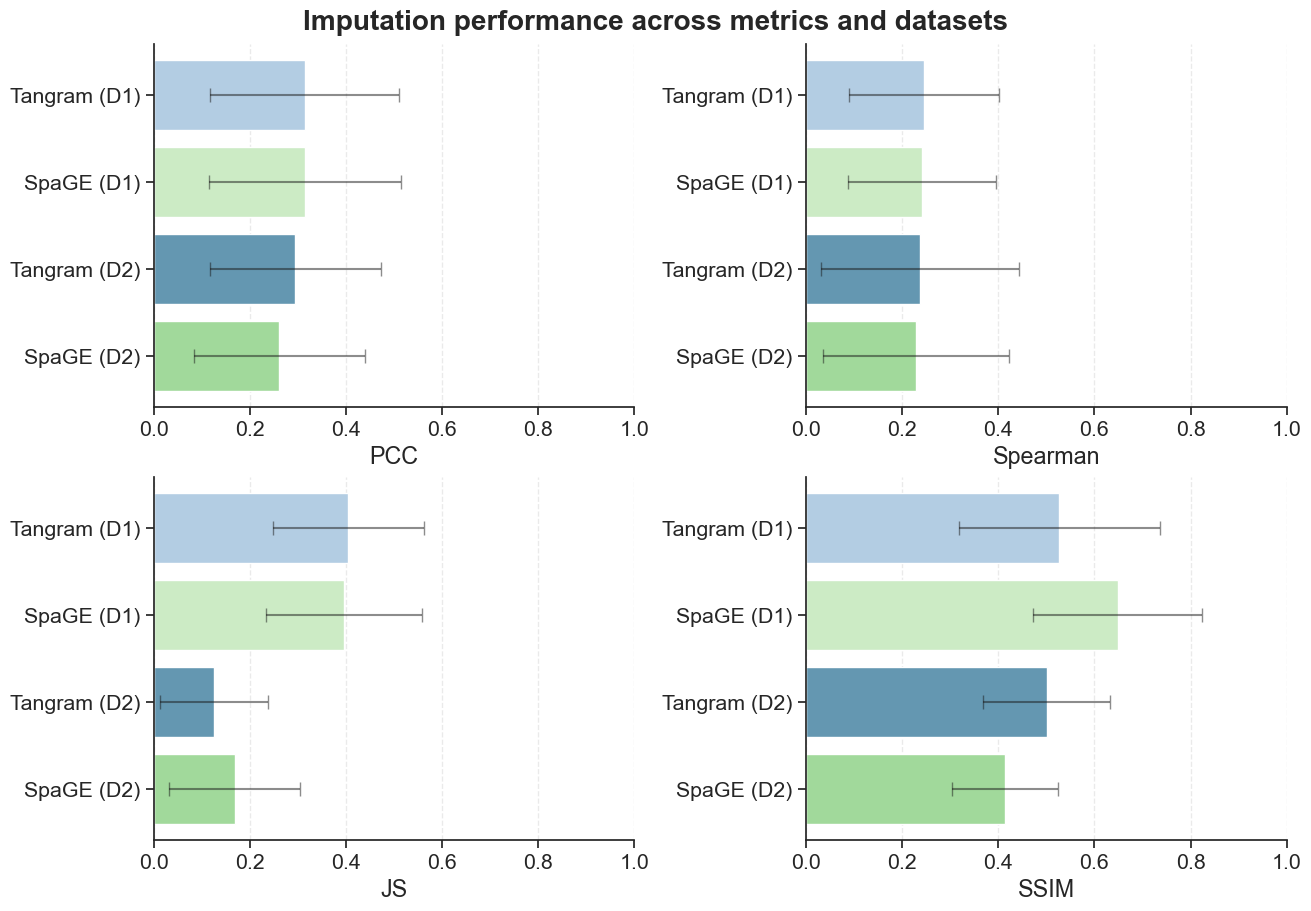

In [4]:
plotting.plot_metric_bars(tidy);

RMSE is on the log-normalised scale and not comparable between datasets; Pearson/Spearman/cosine/SSIM are scale-free.

### Score vs sparsity
Tangram-style diagnostic and AUC of a quadratic fit of score against spatial sparsity (higher = good scores held up for sparse genes).

Tangram (D1)    0.412
SpaGE (D1)      0.409
Tangram (D2)    0.240
SpaGE (D2)      0.213
Name: AUC (PCC vs sparsity), dtype: float64

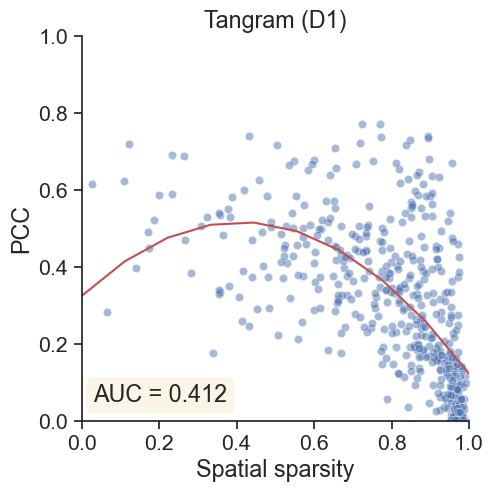

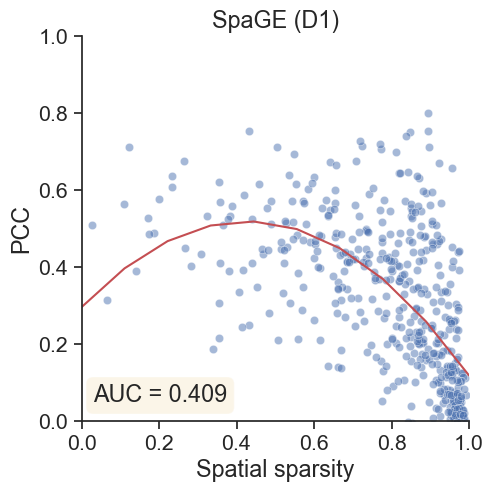

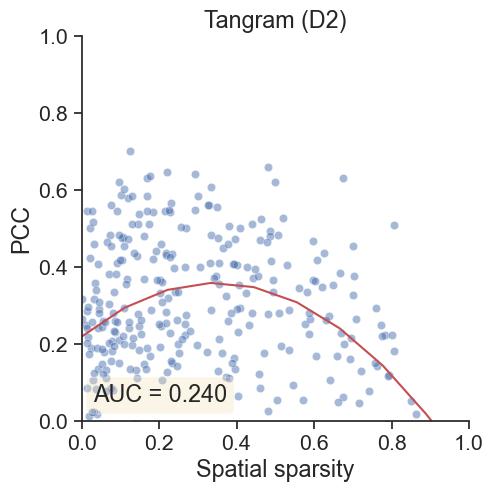

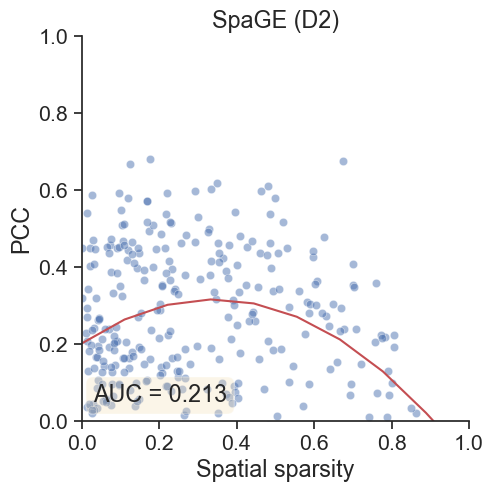

In [5]:
auc = {}
for (m, ds), df in per_condition.items():
    label = f"{config.METHOD_LABELS[m]} ({ds.upper()})"
    auc[label] = metrics.score_sparsity_auc(df["pearson_r"], df["sparsity_sp"])[0]
    plotting.plot_sparsity_auc(df, title=label)
pd.Series(auc, name="AUC (PCC vs sparsity)").round(3)

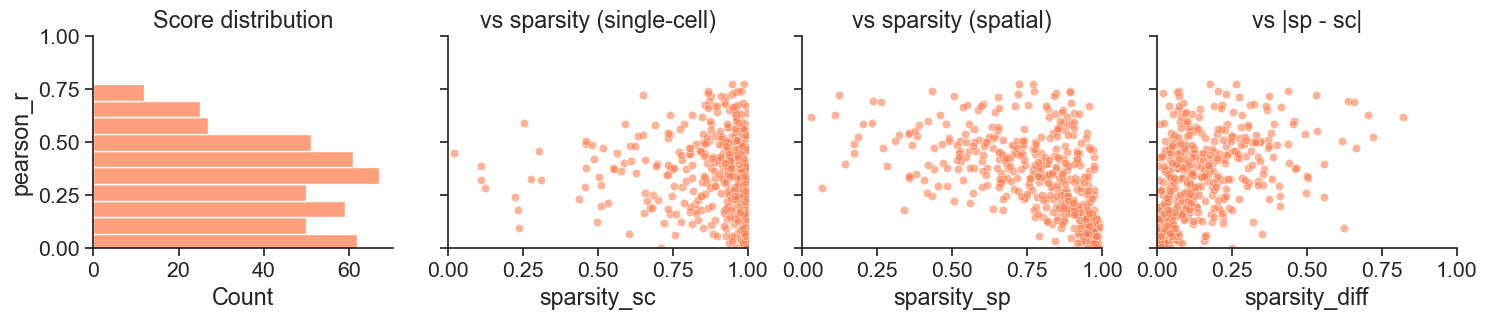

In [6]:
plotting.plot_score_vs_sparsity(per_condition[("tangram", "d1")]);

### Example genes

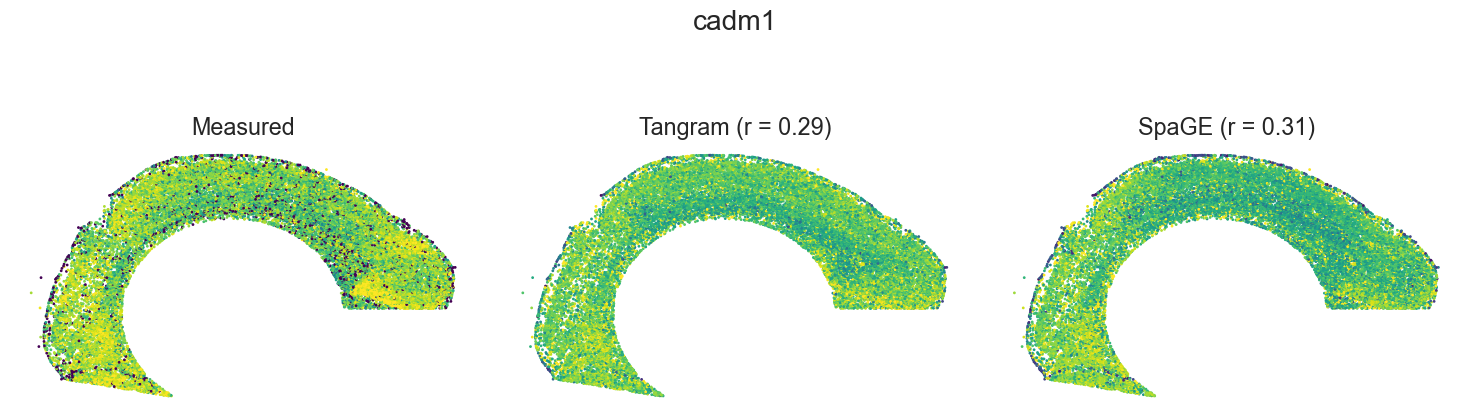

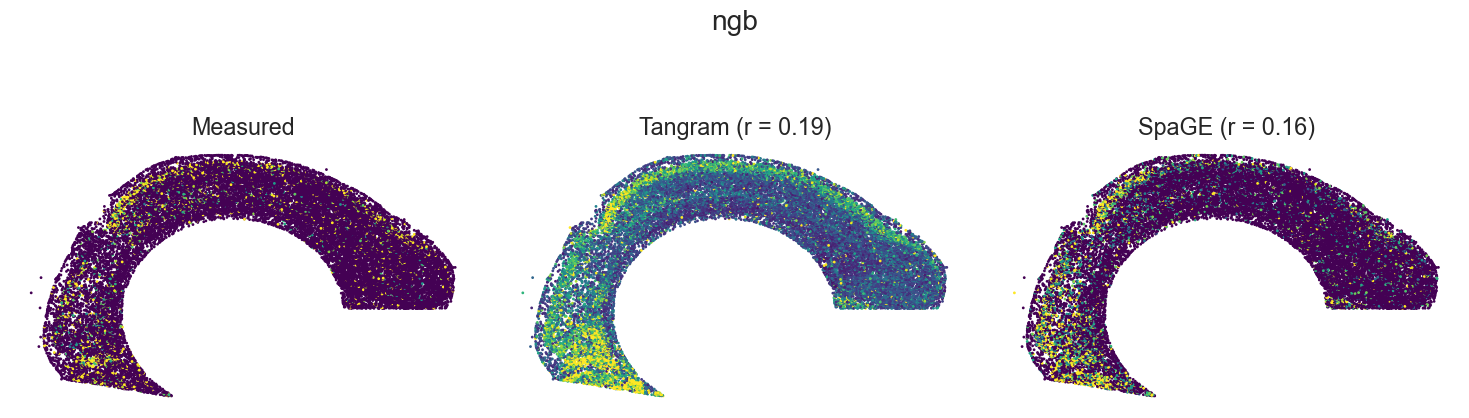

In [7]:
for gene in ["cadm1", "ngb"]:
    ds = "d1"
    scores = {config.METHOD_LABELS[m]: per_condition[(m, ds)].loc[gene, "pearson_r"] for m in config.METHODS}
    plotting.plot_actual_vs_predicted(adatas[ds], gene, scores=scores)

## 2 · Which genes are imputed better than chance?
For each gene, the observed Pearson r is compared with 999 cell-shuffled predictions (one-sided), then BH-corrected across genes.

tangram  d1: 447/464 significant


spage    d1: 445/464 significant


tangram  d2: 281/296 significant


spage    d2: 281/296 significant


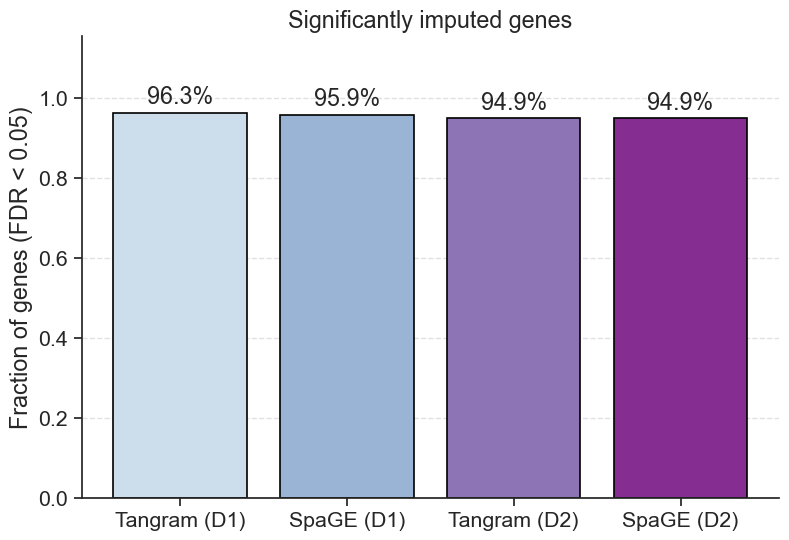

In [8]:
sig = {}
for (m, ds) in per_condition:
    res = stats.permutation_test(adatas[ds].obsm[f"{m}_predictions"], actual[ds], n_permutations=999, seed=0)
    sig[(m, ds)] = res
    per_condition[(m, ds)] = per_condition[(m, ds)].join(res[["p_value", "fdr_p_value", "significant_fdr"]])
    genes = res.index[res["significant_fdr"]]
    out = config.RESULTS_DIR / "significant_genes" / f"significant_genes_{m}_{ds}.txt"
    out.parent.mkdir(parents=True, exist_ok=True)
    out.write_text("\n".join(genes) + "\n")
    print(f"{m:8s} {ds}: {len(genes)}/{len(res)} significant")

tidy = metrics.tidy_metrics(per_condition)
plotting.plot_significant_fraction(tidy);

,shared,only_a,only_b,jaccard
D1,439.0,8.0,6.0,0.969095
D2,276.0,5.0,5.0,0.965035


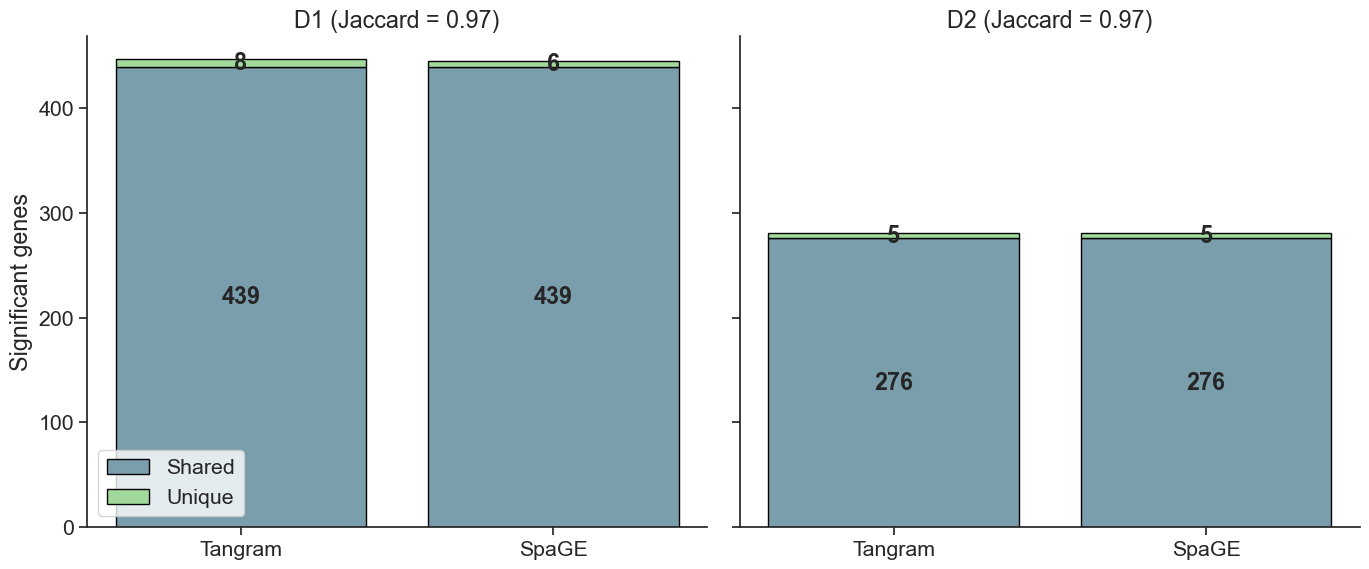

In [9]:
overlaps = {ds.upper(): stats.set_overlap(sig[("tangram", ds)].query("significant_fdr").index,
                                           sig[("spage", ds)].query("significant_fdr").index)
            for ds in DATASETS}
display(pd.DataFrame(overlaps).T)
plotting.plot_overlap(overlaps);

## 3 · Statistical comparisons
**Tangram vs SpaGE** within each dataset (paired over genes, Wilcoxon signed-rank). For JS lower is better.

In [10]:
main_metrics = ["pearson_r", "spearman_r", "js", "ssim"]
pd.concat({ds.upper(): stats.paired_method_test(per_condition[("tangram", ds)], per_condition[("spage", ds)], main_metrics)
           for ds in DATASETS}).round(4)

metric  n_genes        W  p_value  median_diff           better
D1 0   pearson_r      464  47549.0   0.0270      -0.0057  SpaGE > Tangram
   1  spearman_r      464  46726.0   0.0126       0.0045  Tangram > SpaGE
   2          js      464  35975.0   0.0000       0.0087  SpaGE > Tangram
   3        ssim      464  12093.0   0.0000      -0.1059  SpaGE > Tangram
D2 0   pearson_r      296   9254.0   0.0000       0.0319  Tangram > SpaGE
   1  spearman_r      296  17990.0   0.0068       0.0082  Tangram > SpaGE
   2          js      296    920.0   0.0000      -0.0246  Tangram > SpaGE
   3        ssim      296   7915.0   0.0000       0.0875  Tangram > SpaGE

**D1 vs D2** for each method (different gene panels, so unpaired Mann-Whitney U).

In [11]:
pd.concat({config.METHOD_LABELS[m]: stats.unpaired_test(per_condition[(m, "d1")], per_condition[(m, "d2")], main_metrics)
           for m in config.METHODS}).round(4)

metric         U  p_value  median_diff   better
Tangram 0   pearson_r   71241.0   0.3841       0.0374     n.s.
        1  spearman_r   68793.0   0.9674       0.0018     n.s.
        2          js  125817.0   0.0000       0.3187  D2 > D1
        3        ssim   74203.0   0.0609       0.0266     n.s.
SpaGE   0   pearson_r   78351.0   0.0010       0.0761  D1 > D2
        1  spearman_r   71921.0   0.2710       0.0333     n.s.
        2          js  118129.0   0.0000       0.2611  D2 > D1
        3        ssim  119551.0   0.0000       0.2558  D1 > D2

## 4 · What makes a gene imputable?
Moran's I (6-NN, row-standardised) on the measured expression measures how spatially structured each gene is.

In [12]:
moran = {}
for ds in DATASETS:
    a = adatas[ds]
    moran[ds] = pd.Series(stats.morans_i(a.obsm["spatial"], actual[ds].to_numpy()), index=a.var_names, name="moran_i")
tidy["moran_i"] = [moran[ds.lower()][g] for ds, g in zip(tidy["dataset"], tidy["gene"])]

tidy.to_csv(config.RESULTS_DIR / "gene_metrics.csv", index=False)
print("saved results/gene_metrics.csv", tidy.shape)

saved results/gene_metrics.csv (1520, 17)


### Do the two sections differ in gene properties?

,metric,U,p_value,median_diff,better
0,sparsity_sp,128122.0,0.0,0.6234,D1 > D2
1,moran_i,50882.0,0.0,-0.0438,D2 > D1


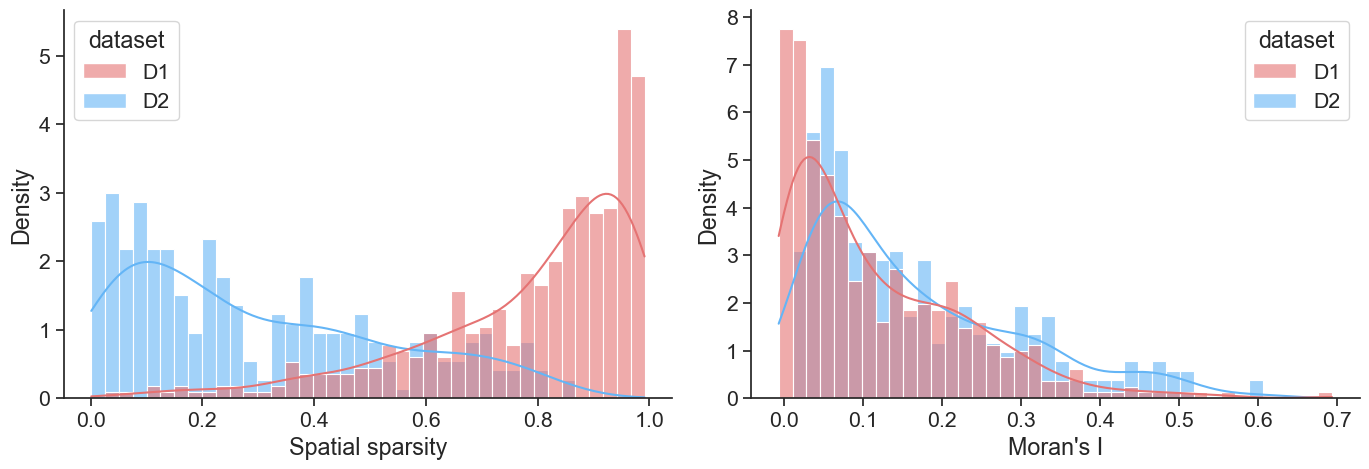

In [13]:
props = tidy[tidy["method"] == "Tangram"][["dataset", "gene", "sparsity_sp", "moran_i"]]
display(stats.unpaired_test(props[props.dataset == "D1"], props[props.dataset == "D2"], ["sparsity_sp", "moran_i"]).round(4))
plotting.plot_property_distributions(props);

### Performance vs gene properties

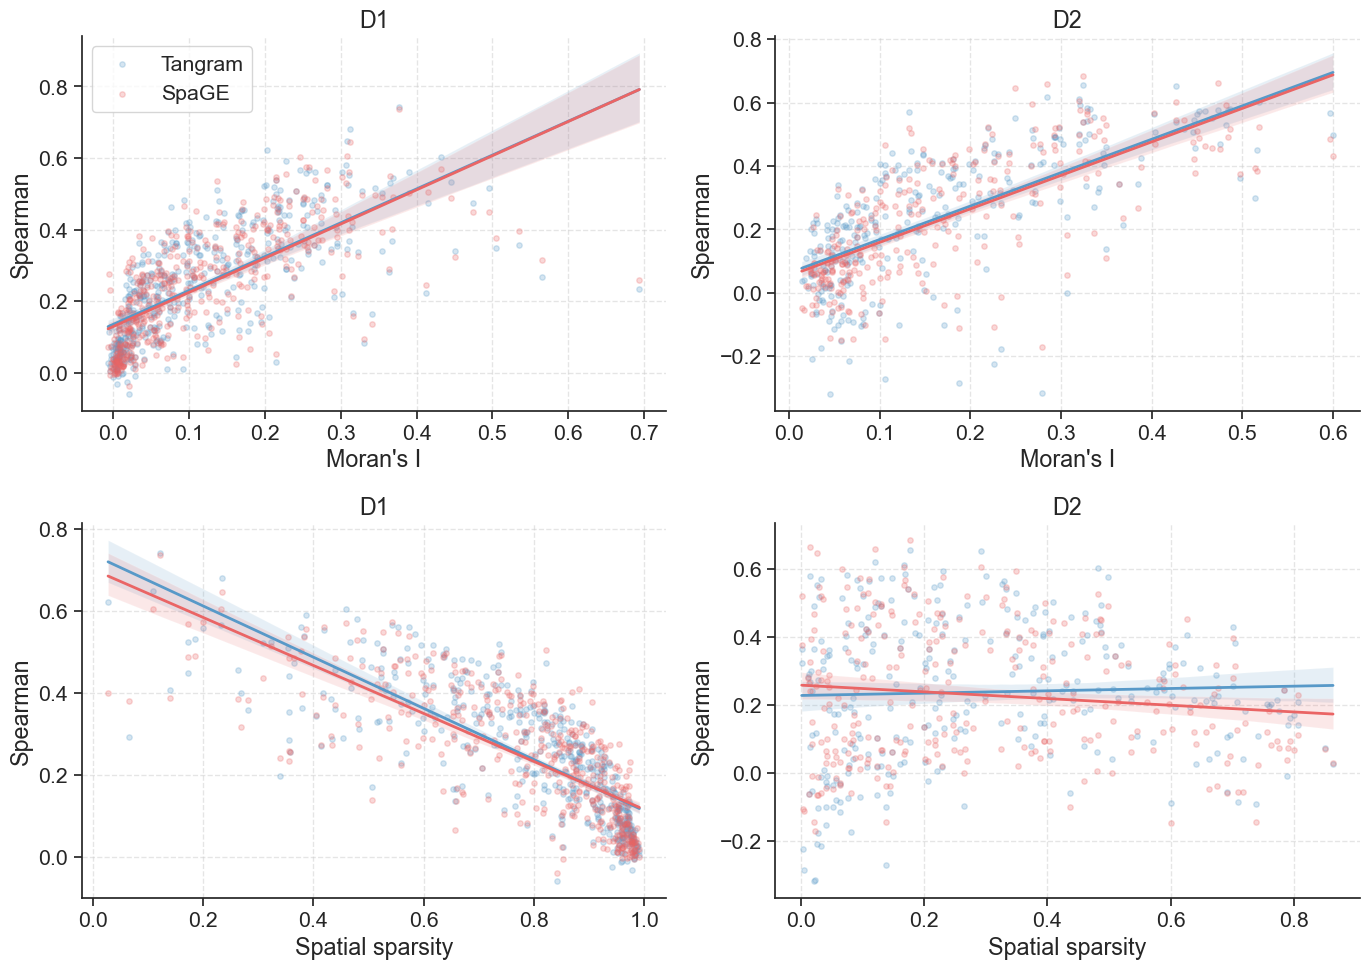

In [14]:
plotting.plot_property_vs_score(tidy, score="spearman_r");

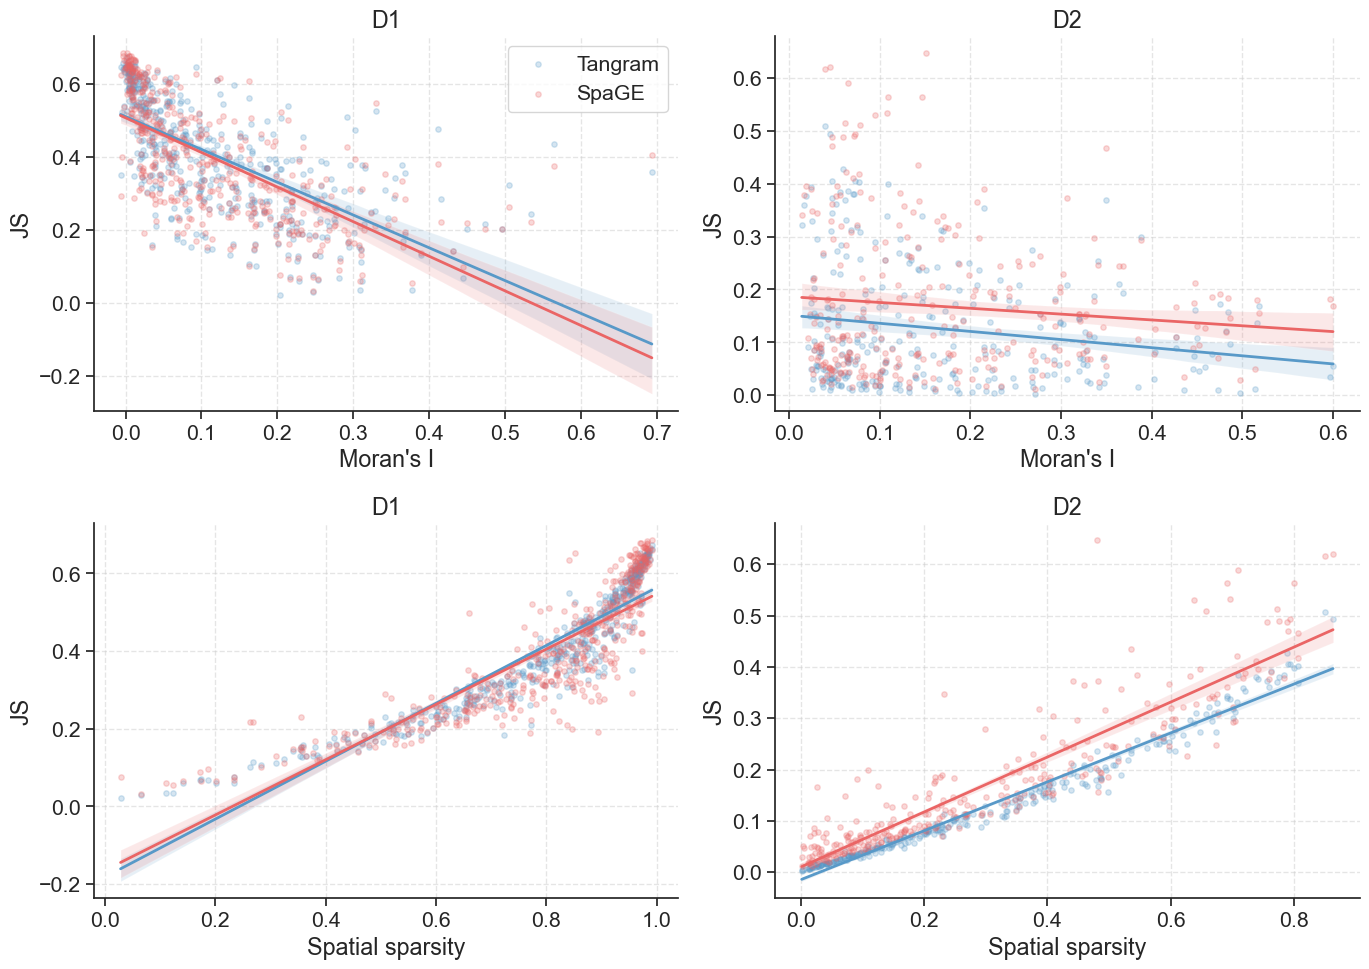

In [15]:
plotting.plot_property_vs_score(tidy, score="js");

,label,x,y,r,p_value
0,Tangram (D1),sparsity_sp,spearman_r,-0.7825,0.0000
1,Tangram (D1),moran_i,spearman_r,0.6887,0.0000
2,Tangram (D1),sparsity_sp,js,0.9238,0.0000
3,Tangram (D1),moran_i,js,-0.6480,0.0000
4,SpaGE (D1),sparsity_sp,spearman_r,-0.7444,0.0000
5,SpaGE (D1),moran_i,spearman_r,0.7052,0.0000
6,SpaGE (D1),sparsity_sp,js,0.8547,0.0000
7,SpaGE (D1),moran_i,js,-0.6625,0.0000
8,Tangram (D2),sparsity_sp,spearman_r,0.0386,0.5087
9,Tangram (D2),moran_i,spearman_r,0.6737,0.0000


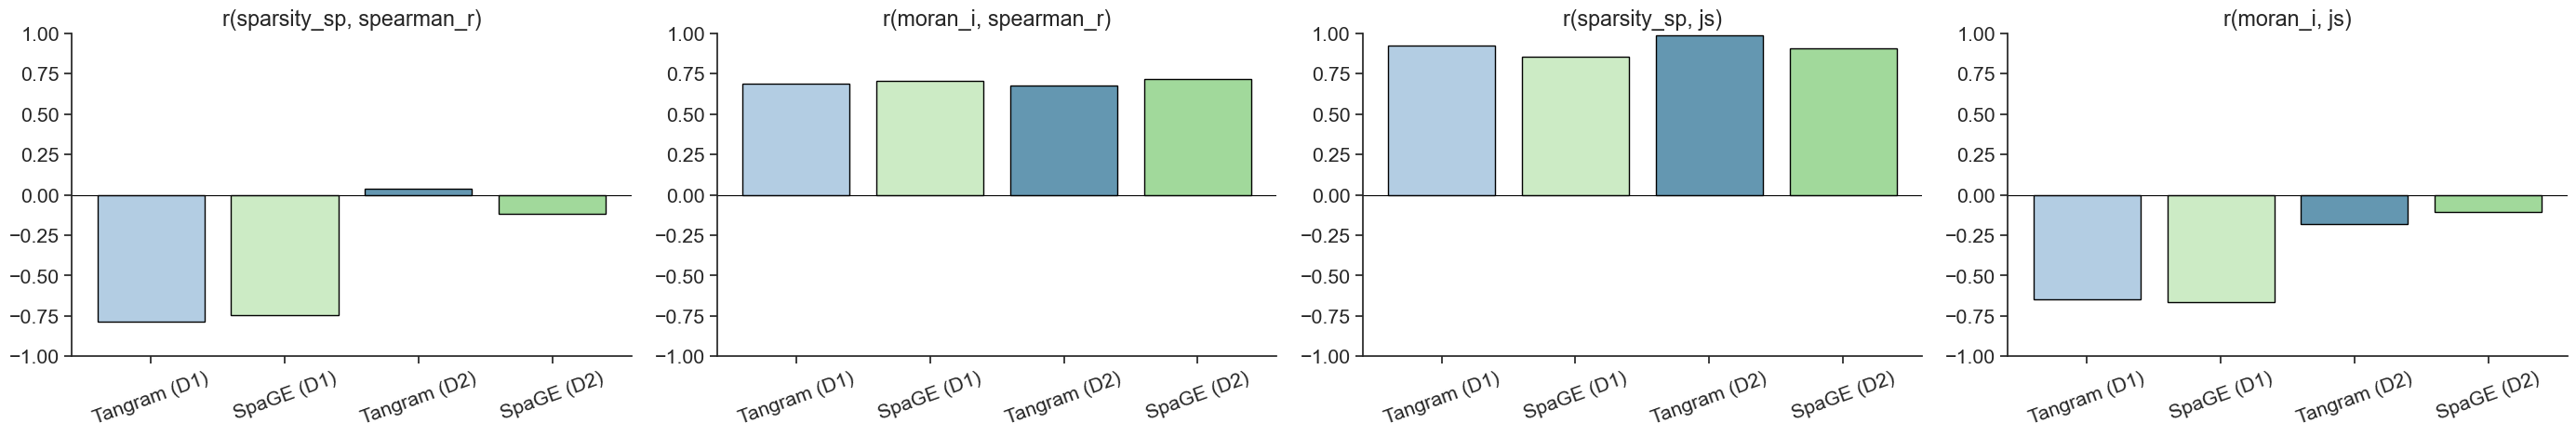

In [16]:
corr = stats.correlation_table(tidy, [("sparsity_sp", "spearman_r"), ("moran_i", "spearman_r"),
                                       ("sparsity_sp", "js"), ("moran_i", "js")])
display(corr.round(4))
plotting.plot_correlation_bars(corr);

### Sparsity vs spatial structure

In [17]:
for ds, d in props.groupby("dataset"):
    r, p = st.pearsonr(d["sparsity_sp"], d["moran_i"])
    print(f"{ds}: r = {r:.3f}, p = {p:.2e}")

D1: r = -0.572, p = 1.35e-41
D2: r = -0.118, p = 4.31e-02


## Summary

- **Overall performance is close and depends on the dataset.** In D1, SpaGE scores higher on PCC, JS and especially SSIM (Tangram is marginally higher on Spearman); in D2, Tangram is better on all four metrics (paired Wilcoxon, section 3). Effect sizes are small apart from SSIM.
- **Almost every gene is imputed better than chance**: 96% (D1) and 95% (D2) after FDR, with ~97% overlap between the two methods' significant sets.
- **Spatial structure is the consistent determinant.** Moran's I correlates with Spearman accuracy in both sections for both methods (r ≈ 0.67-0.72). Sparsity predicts accuracy strongly in D1 (r ≈ -0.75) but hardly at all in D2, where genes are much less sparse.
- JS divergence tracks sparsity almost perfectly (r = 0.85-0.98), so it mainly reflects how sparse a gene is, not how well its pattern is recovered.